<div class="streaming-cover" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><div style="background:linear-gradient(125deg,#23262D 0%,#292D35 65%,#353943 100%);color:#FAF9F7;padding:42px 38px 32px;border-radius:20px;position:relative;border:1px solid #454A55"><div style="display:flex;justify-content:space-between;align-items:center;gap:20px;border-bottom:1px solid #606570;padding-bottom:19px"><span style="font:600 12px system-ui;letter-spacing:3px;color:#F6B4A9">ЕЩЕ СЕРИЮ И СПАТЬ</span><span style="font:12px ui-monospace;color:#D2D4DA">СЕЗОН 01 / POSTGRESQL</span></div>
<div style="font:700 56px/1.08 system-ui;letter-spacing:-2px;margin:34px 0 23px;color:#ffffff">Хорошие истории.<br/><span style="color:#F08272">Точные запросы.</span></div>
<p style="font:18px/1.65 system-ui;color:#EBECEF;max-width:670px">Помогите редакции онлайн-кинотеатра выбрать,<br/>что предложить зрителям на главной.</p>
<div style="display:flex;flex-wrap:wrap;gap:10px;margin-top:27px"><span style="padding:9px 15px;border-radius:30px;background:#F08272;color:#292D35;font:600 12px system-ui">07 ЭПИЗОДОВ · 01 КЕЙС</span></div></div>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Вы — аналитики онлайн-кинотеатра</h3>
<p style="margin:10px 0 15px;line-height:1.65">В учебном сервисе «Еще серию и спать» редакция обновляет главную страницу. У вас есть каталог фильмов и сериалов, история запусков и пользовательские оценки. Нужно помочь редакции обосновать выбор произведений этими данными.</p>
<div style="background:#FFF5F2;border-left:4px solid #A34235;padding:16px 20px;border-radius:10px;margin:18px 0"><p style="margin:10px 0 15px;line-height:1.65"><strong>Главный вопрос:</strong> что предложить зрителям на главной странице и почему?</p>
</div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>К финалу:</strong> семь SQL-запросов и <a href="#editor-brief" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">короткая записка редакции из четырёх выводов</a>: что подойдёт для короткого вечера, что востребовано у разных зрителей, что осталось без запусков и как учитывать личную шкалу оценок.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Чему учимся:</strong> переводить вопрос редакции в SQL-запрос, понимать смысл одной строки результата и объяснять полученные числа.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Как смотреть этот сезон</h3>
<p style="margin:10px 0 15px;line-height:1.65">Откройте ноутбук в <strong>JupyterLab / Notebook с Python kernel </strong> или загрузите его в <strong>Google Colab</strong>. Запускайте ячейки сверху вниз: <strong>Shift + Enter</strong>. В Colab используйте обычную размещённую CPU-среду.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Пароли, адрес сервера и отдельная установка PostgreSQL не нужны.</strong> Первая ячейка сама устанавливает компоненты и запускает отдельный PostgreSQL. Первый запуск требует интернета и обычно занимает несколько минут. Уже установленного Python/Jupyter это не заменяет. Автоустановка рассчитана на Python 3.10–3.14 и платформы с готовыми пакетами; если локальная среда несовместима, используйте Colab.</p>
<p style="margin:10px 0 15px;line-height:1.65">Кадры и учебные данные находятся внутри файла. После установки ноутбук не обращается к внешним сайтам. Временная база воссоздаётся из ноутбука; сохраняйте свои запросы в ячейках.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Формат:</strong> вопрос редакции → короткая теория → пример → ваш запрос → вывод.</p>
</div>


In [1]:
# Запустите один раз. Настройки менять не нужно.
import sys, subprocess, importlib.util, importlib, tempfile
from pathlib import Path

if sys.version_info < (3, 10):
    raise RuntimeError("Нужен Python 3.10+; можно открыть файл в Google Colab.")
backend_name = "pgserver" if sys.version_info < (3, 13) else "pgembed"
backend_package = "pgserver==0.1.4" if backend_name == "pgserver" else "pgembed==0.2.0"
packages = {"psycopg": "psycopg[binary]>=3.2,<4", "ipywidgets": "ipywidgets>=8,<9", backend_name: backend_package}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Первый запуск: устанавливаем PostgreSQL и библиотеки…")
    result = subprocess.run([sys.executable, "-m", "pip", "install", "--only-binary=:all:", *missing], capture_output=True, text=True)
    if result.returncode:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError("Автоустановка не завершилась. Проверьте интернет; для несовместимого локального Python откройте файл в Colab.")
    importlib.invalidate_caches()
import psycopg
import ipywidgets as widgets
from IPython.display import display, HTML
from IPython.core.magic import register_cell_magic
from html import escape
import re

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

if "STREAMING_SERVER" not in globals():
    STREAMING_DIR = Path(tempfile.mkdtemp(prefix="eseries-pg-"))
    STREAMING_SERVER = importlib.import_module(backend_name).get_server(STREAMING_DIR, cleanup_mode="stop")
if "db" in globals() and not db.closed:
    db.close()
db = psycopg.connect(STREAMING_SERVER.get_uri(), autocommit=True)
db.execute("SET statement_timeout = '10s'")
SQL_ERRORS = []
def show_table(headers, rows):
    head = ''.join('<th style="text-align:left;padding:12px 14px;background:#292D35;color:#ffffff;font-weight:600">'+escape(str(h))+'</th>' for h in headers)
    body = ''.join('<tr style="background:'+('#F2F3F5' if i%2 else '#ffffff')+'">'+''.join('<td style="padding:10px 14px;color:#292D35;border-bottom:1px solid #E5E6E9">'+ ('<i style="color:#A34235">NULL</i>' if v is None else escape(str(v))) +'</td>' for v in row)+'</tr>' for i,row in enumerate(rows))
    display(HTML('<div style="overflow:auto;border:1px solid #DDDFE4;border-radius:12px"><table style="width:100%;font-family:system-ui;font-size:15px;border-collapse:collapse"><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table></div><p style="font:12px system-ui;color:#666A73;letter-spacing:1px">РЕЗУЛЬТАТ · СТРОК: '+str(len(rows))+'</p>'))

@register_cell_magic
def sql(line, cell):
    if not re.sub(r'--[^\n]*', '', cell).strip():
        print("Здесь будет ваш SQL. Можно переходить дальше или написать решение.")
        return
    try:
        with db.transaction():
            db.execute("SET TRANSACTION READ ONLY")
            cur = db.execute(cell, prepare=False)
            if cur.description:
                show_table([c.name for c in cur.description], cur.fetchall())
    except psycopg.Error as exc:
        SQL_ERRORS.append(str(exc))
        print("PostgreSQL:", exc.diag.message_primary)
        if exc.diag.message_hint:
            print("Подсказка:", exc.diag.message_hint)
        print("Исправьте запрос и запустите эту ячейку ещё раз. Подключение работает.")

display(HTML('<div style="padding:16px;background:#F1F2F4;color:#292D35;border-radius:12px"><b>Готово.</b> PostgreSQL '+escape(db.info.server_version.__str__())+' запущен. Пароль вводить не нужно.</div>'))

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">Пролог. Знакомимся с каталогом</h2>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Начнём с киноразминки.</strong> По сюжету после обновления у пяти карточек исчезли названия, а кадры сохранились. Узнайте произведения, с данными о которых будете работать дальше.</p>
<p style="margin:10px 0 15px;line-height:1.65">На карточку примерно минута. 
    Сначала деталь, затем более широкий фрагмент, затем полный кадр. </p>
<p style="margin:10px 0 15px;line-height:1.65">«Угадали — восстановить» засчитывает 3 / 2 / 1 балл по текущей подсказке. «Показать ответ» открывает карточку без баллов. Следующая карточка доступна после раскрытия текущей. Перезапуск ячейки начинает игру заново.</p>
<p style="margin:10px 0 15px;line-height:1.65">Игра знакомит с каталогом. Все учебные таблицы загрузятся ниже независимо от набранных баллов; при необходимости разминку можно пропустить.</p>
</div>


In [8]:
GAME = [{'id': 104, 'title': 'Начало', 'data': '...', 'pos': ('43% 51%', '43% 51%'), 'sizes': ['450% auto', '180% auto', 'contain']}, {'id': 122, 'title': 'Бойцовский клуб', 'data': '...', 'pos': ('49% 46%', '50% 70%'), 'sizes': ['600% auto', '280% auto', 'contain']}, {'id': 112, 'title': 'Интерстеллар', 'data': '...', 'pos': ('44% 70%', '50% 55%'), 'sizes': ['450% auto', '180% auto', 'contain']}, {'id': 115, 'title': 'Друзья', 'data': '...', 'pos': ('30% 77%', '50% 50%'), 'sizes': ['450% auto', '180% auto', 'contain']}, {'id': 118, 'title': 'Шрек', 'data': '...', 'pos': ('47% 35%', '48% 52%'), 'sizes': ['500% auto', '240% auto', 'contain']}]
DULOC_VIDEO = '...'

game_state = dict(index=0, stage=0, revealed=False, score=0, restored=0)
screen = widgets.HTML()
scene_player = widgets.HTML()
next_hint = widgets.Button(description="Следующая подсказка", layout=widgets.Layout(width="210px"))
win = widgets.Button(description="Угадали — восстановить", button_style="success", layout=widgets.Layout(width="220px"))
reveal = widgets.Button(description="Показать ответ", layout=widgets.Layout(width="170px"))
next_card = widgets.Button(description="Следующая карточка →", layout=widgets.Layout(width="220px"))
def render_game():
    s=game_state; g=GAME[s['index']]
    size=g['sizes'][s['stage']]
    pos=g['pos'][min(s['stage'],1)] if s['stage']<2 else "center"
    title=escape(g['title']) if s['revealed'] else "Название потеряно"
    label=["01 / ДЕТАЛЬ", "02 / ШИРЕ", "03 / ПОЛНЫЙ КАДР"][s['stage']]
    if s['revealed']: size="contain"; pos="center"; label="КАРТОЧКА ВОССТАНОВЛЕНА"
    done = s['restored']==len(GAME)
    screen.value=f"""<div style="max-width:920px;background:#292D35;color:#f8fafc;padding:22px;border-radius:18px;font-family:system-ui">
    <div style="color:#F6B4A9;font-size:13px;letter-spacing:2px">ЕЩЕ СЕРИЮ И СПАТЬ · ВОССТАНОВЛЕНО {s['restored']} / 5 · БАЛЛЫ {s['score']} / 15</div>
    <h2 style="color:white">#{g['id']} · {title}</h2>
    <div role="img" aria-label="Киноподсказка" style="height:380px;background-color:#05070b;background-image:url('{g['data']}');background-repeat:no-repeat;background-size:{size};background-position:{pos};border-radius:10px"></div>
    <p style="color:#F6B4A9">{label}</p>
    {"<p>Каталог восстановлен. Названия вернулись, ID остались прежними. Переходим к базе.</p>" if done else ""}</div>"""
    next_hint.disabled=s['revealed'] or s['stage']==2
    win.disabled=reveal.disabled=s['revealed']
    next_card.disabled=not s['revealed'] or s['index']==len(GAME)-1
    if g['id']==118 and s['revealed']:
        scene_player.value = '<div style="max-width:920px;padding:18px;background:#F4F4F5;color:#292D35;border-radius:12px"><h3>Вот откуда этот кадр: стенд в Дюлоке</h3><p>Нажмите ▶ в плеере. Фрагмент на английском; звук включается только при запуске.</p><video controls playsinline preload="none" style="width:100%;max-width:880px" src="'+DULOC_VIDEO+'">Ваш интерфейс не поддерживает встроенное видео.</video><p style="font-size:12px"><a href="https://clip.cafe/shrek-2001/such-a-perfect-town/" target="_blank">Источник: Clip.Cafe · Shrek (2001)</a></p></div>'
    else:
        scene_player.value = ''
def hint_click(_):
    if not game_state['revealed'] and game_state['stage']<2:
        game_state['stage']+=1
    render_game()
def reveal_click(guessed):
    if not game_state['revealed']:
        game_state['revealed']=True; game_state['restored']+=1
        if guessed: game_state['score']+=3-game_state['stage']
    render_game()
def next_click(_):
    if game_state['revealed'] and game_state['index']<len(GAME)-1:
        game_state.update(index=game_state['index']+1,stage=0,revealed=False)
    render_game()
next_hint.on_click(hint_click); win.on_click(lambda _: reveal_click(True))
reveal.on_click(lambda _: reveal_click(False)); next_card.on_click(next_click)
render_game()
display(widgets.VBox([screen,widgets.HBox([next_hint,win]),widgets.HBox([reveal,next_card]),scene_player]))

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">От карточек — к вопросам редакции</h2>
<p style="margin:10px 0 15px;line-height:1.65">Теперь разберёмся, на чём основан выбор редакции: <strong>titles</strong> описывает произведения, <strong>views</strong> показывает запуски, <strong>users</strong> помогает понять, кто смотрел, а <strong>ratings</strong> — какие оценки оставили пользователи. Семь заданий постепенно собирают эти сведения в понятные отчёты.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Все пользователи, просмотры, оценки, рейтинг каталога и значения длительности — учебные.</strong> Названия произведений настоящие. Это не реальные показатели стриминга или IMDb. Жанр один, условный; у сериала длительность — ориентир одной серии. Эпизоды отдельно не моделируем.</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">users (1) ─────&lt; views &gt;───── (1) titles
  │                               │
  └───────&lt; ratings &gt;──────────────┘
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">1 → много</code>: одному пользователю соответствуют многие просмотры; одному произведению — многие просмотры. Между пользователями и произведениями получается «многие ко многим» через <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views</code>.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Таблица</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Одна строка — это…</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Столбцы</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">titles</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Произведение</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">kind</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">genre</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">duration_minutes</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">catalog_rating</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">users</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Пользователь</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">name</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">city</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Один запуск просмотра</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">view_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">started_at</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">watched_minutes</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ratings</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Оценка пользователя произведению</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">rating_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">score</code></td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Первичный ключ (PK)</strong> различает строки: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code> уникален и не пуст. <strong>Внешний ключ (FK)</strong> указывает на существующую запись: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views.title_id → titles.title_id</code>. Имена могут повторяться; соединяем по ID.</p>
<p style="margin:10px 0 15px;line-height:1.65">Повторный запуск создаёт новую строку <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views</code>. Нулевые минуты — запуск без просмотра. У некоторых произведений нет просмотров; у некоторых — только старые. Оценки есть не у всех. Есть два разных пользователя по имени Саша.</p>
<p style="margin:10px 0 15px;line-height:1.65">Для задач «неделя» всегда означает <strong>5–11 октября 2026 включительно</strong>, то есть <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">[2026-10-05 00:00, 2026-10-12 00:00)</code>. Даты не зависят от дня проведения занятия.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Два разных показателя:</strong> catalog_rating — заданный учебный рейтинг каталога для подборки в задаче 1; score — отдельная пользовательская оценка для задач 6–7. У оценок нет даты, поэтому в этих двух задачах используем все 18 записей.</p>
</div>

In [4]:
# Повторный запуск сбрасывает только временные учебные таблицы этой сессии.
# Старые ответы в ячейках ноутбука не изменяются.
if not db.closed:
    db.close()
db = psycopg.connect(STREAMING_SERVER.get_uri(), autocommit=True)
db.execute("SET statement_timeout = '10s'")
DDL = """
CREATE TEMP TABLE titles (
 title_id integer PRIMARY KEY, title text NOT NULL, kind text NOT NULL,
 genre text NOT NULL, duration_minutes integer NOT NULL CHECK(duration_minutes>0),
 catalog_rating numeric(3,1) NOT NULL CHECK(catalog_rating BETWEEN 0 AND 10));
CREATE TEMP TABLE users (user_id integer PRIMARY KEY, name text NOT NULL, city text NOT NULL);
CREATE TEMP TABLE views (
 view_id integer PRIMARY KEY, user_id integer NOT NULL REFERENCES users(user_id),
 title_id integer NOT NULL REFERENCES titles(title_id), started_at timestamp NOT NULL,
 watched_minutes integer NOT NULL CHECK(watched_minutes>=0));
CREATE TEMP TABLE ratings (
 rating_id integer PRIMARY KEY, user_id integer NOT NULL REFERENCES users(user_id),
 title_id integer NOT NULL REFERENCES titles(title_id), score integer NOT NULL CHECK(score BETWEEN 1 AND 10),
 UNIQUE(user_id,title_id));
"""
with db.transaction():
    db.execute(DDL, prepare=False)
    with db.cursor() as c:
        c.executemany("INSERT INTO titles VALUES (%s, %s, %s, %s, %s, %s)", [(101, 'Во все тяжкие', 'сериал', 'драма', 47, 9.5), (102, 'Игра престолов', 'сериал', 'фэнтези', 57, 9.1), (103, 'Очень странные дела', 'сериал', 'фантастика', 50, 8.7), (104, 'Начало', 'фильм', 'фантастика', 148, 8.8), (105, 'Офис', 'сериал', 'комедия', 22, 9.0), (107, 'Матрица', 'фильм', 'фантастика', 136, 8.7), (112, 'Интерстеллар', 'фильм', 'фантастика', 169, 8.8), (115, 'Друзья', 'сериал', 'комедия', 22, 8.9), (118, 'Шрек', 'фильм', 'комедия', 90, 8.0), (120, 'Крёстный отец', 'фильм', 'драма', 175, 9.2), (121, 'Побег из Шоушенка', 'фильм', 'драма', 142, 9.3), (122, 'Бойцовский клуб', 'фильм', 'триллер', 139, 8.8), (123, 'Остров проклятых', 'фильм', 'триллер', 138, 8.2), (124, 'Гарри Поттер и философский камень', 'фильм', 'фэнтези', 152, 7.9), (125, 'Шоу Трумана', 'фильм', 'драма', 103, 8.2), (126, 'Назад в будущее', 'фильм', 'фантастика', 116, 8.5)])
        c.executemany("INSERT INTO users VALUES (%s, %s, %s)", [(1, 'Аня', 'Москва'), (2, 'Марк', 'Казань'), (3, 'Саша', 'Москва'), (4, 'Лена', 'Тверь'), (5, 'Саша', 'Казань'), (6, 'Ника', 'Москва'), (7, 'Олег', 'Тверь'), (8, 'Ира', 'Казань')])
        c.executemany("INSERT INTO views VALUES (%s, %s, %s, %s, %s)", [(1, 2, 105, '2026-10-05 10:00:00', 22), (2, 2, 105, '2026-10-06 11:00:00', 22), (3, 2, 105, '2026-10-07 12:00:00', 22), (4, 2, 105, '2026-10-08 13:00:00', 22), (5, 2, 105, '2026-10-09 14:00:00', 22), (6, 2, 105, '2026-10-10 15:00:00', 22), (7, 2, 105, '2026-10-11 16:00:00', 22), (8, 2, 105, '2026-10-05 17:00:00', 22), (9, 2, 105, '2026-10-06 18:00:00', 22), (10, 2, 105, '2026-10-07 19:00:00', 22), (11, 2, 105, '2026-10-08 20:00:00', 22), (12, 3, 105, '2026-10-08 20:00:00', 18), (13, 1, 101, '2026-10-05 20:00:00', 40), (14, 2, 101, '2026-10-06 20:00:00', 41), (15, 3, 101, '2026-10-07 20:00:00', 42), (16, 4, 101, '2026-10-08 20:00:00', 43), (17, 5, 101, '2026-10-09 20:00:00', 40), (18, 6, 101, '2026-10-10 20:00:00', 41), (19, 1, 101, '2026-10-11 20:00:00', 42), (20, 4, 101, '2026-10-05 20:00:00', 43), (21, 1, 104, '2026-10-05 20:00:00', 148), (22, 3, 104, '2026-10-06 20:00:00', 90), (23, 6, 104, '2026-10-10 20:00:00', 148), (24, 1, 107, '2026-10-07 20:00:00', 136), (25, 2, 107, '2026-10-08 20:00:00', 100), (26, 5, 107, '2026-10-11 20:00:00', 136), (27, 1, 112, '2026-10-06 20:00:00', 169), (28, 4, 112, '2026-10-09 20:00:00', 169), (29, 1, 115, '2026-10-05 20:00:00', 22), (30, 3, 115, '2026-10-07 20:00:00', 22), (31, 5, 115, '2026-10-09 20:00:00', 20), (32, 6, 115, '2026-10-10 20:00:00', 22), (33, 2, 118, '2026-10-08 20:00:00', 90), (34, 3, 118, '2026-10-09 20:00:00', 90), (35, 5, 118, '2026-10-10 20:00:00', 45), (36, 7, 118, '2026-10-11 20:00:00', 90), (37, 3, 102, '2026-10-04 20:00:00', 57), (38, 4, 102, '2026-10-12 20:00:00', 57), (39, 2, 103, '2026-10-06 20:00:00', 0), (40, 6, 103, '2026-10-09 20:00:00', 48), (41, 1, 122, '2026-10-08 20:00:00', 139), (42, 4, 123, '2026-10-10 20:00:00', 100), (43, 2, 124, '2026-10-03 20:00:00', 152), (44, 5, 125, '2026-10-07 20:00:00', 103), (45, 6, 126, '2026-10-11 20:00:00', 116), (46, 7, 126, '2026-10-11 20:00:00', 80)])
        c.executemany("INSERT INTO ratings VALUES (%s, %s, %s, %s)", [(1, 1, 104, 9), (2, 1, 112, 10), (3, 1, 115, 8), (4, 1, 118, 7), (5, 2, 105, 10), (6, 2, 101, 8), (7, 2, 107, 7), (8, 3, 104, 8), (9, 3, 118, 6), (10, 3, 115, 7), (11, 4, 112, 9), (12, 4, 123, 8), (13, 4, 101, 10), (14, 5, 107, 9), (15, 5, 125, 8), (16, 6, 103, 8), (17, 6, 126, 10), (18, 7, 118, 9)])
print("Готово: 16 произведений, 8 пользователей, 46 запусков и 18 оценок. Данные восстановлены.")

Готово: 16 произведений, 8 пользователей, 46 запусков и 18 оценок. Данные восстановлены.


<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Первый запрос</h3>

<p style="margin:10px 0 15px;line-height:1.65">В SQL-ячейке первая строка <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">%%sql</code> передаёт текст PostgreSQL. </p>
<p style="margin:10px 0 15px;line-height:1.65">Сначала осмотрим все 16 произведений: какие у них ID, тип, жанр, длительность и рейтинг. Это исходный каталог, из которого редакция будет собирать подборки.</p>
</div>

In [5]:
%%sql
SELECT * FROM titles ORDER BY title_id;

title_id,title,kind,genre,duration_minutes,catalog_rating
101,Во все тяжкие,сериал,драма,47,9.5
102,Игра престолов,сериал,фэнтези,57,9.1
103,Очень странные дела,сериал,фантастика,50,8.7
104,Начало,фильм,фантастика,148,8.8
105,Офис,сериал,комедия,22,9.0
107,Матрица,фильм,фантастика,136,8.7
112,Интерстеллар,фильм,фантастика,169,8.8
115,Друзья,сериал,комедия,22,8.9
118,Шрек,фильм,комедия,90,8.0
120,Крёстный отец,фильм,драма,175,9.2


<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">Маршрут: от вопроса редакции к решению</h2>
<p style="margin:10px 0 15px;line-height:1.65">В каждом эпизоде вы отвечаете на один вопрос редакции: <strong>разбираете приём → изучаете пример → пишете свой запрос → формулируете вывод</strong>. Пример и задание могут использовать разные таблицы: из примера переносим способ решения. После задания сохраните наблюдение для итоговой записки.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead><tr><th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Эпизод и SQL-приём</th><th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Вопрос редакции</th><th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Что получим</th></tr></thead>
<tbody>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep1" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">01 · Подборка на вечер</a><br/>SELECT, WHERE, ORDER BY</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Что можно посмотреть за два часа?</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Список фильмов, подходящих по длительности, жанру и рейтингу.</td></tr>
<tr><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep2" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">02 · Реальная аудитория</a><br/>GROUP BY, HAVING</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Какие произведения смотрели разные люди?</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Показатели произведений с тремя и более зрителями за неделю.</td></tr>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep3" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">03 · От ID к событиям</a><br/>INNER JOIN</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Кто и что смотрел? Проверим московских зрителей.</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Журнал запусков с именами и названиями для проверки деталей.</td></tr>
<tr><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep4" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">04 · Без внимания</a><br/>LEFT JOIN, NULL</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Что за неделю ни разу не включили?</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Список произведений без запусков, включая те, что смотрели раньше.</td></tr>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep5" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">05 · Полная картина</a><br/>JOIN + GROUP BY</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Совпадают ли лидеры по запускам и по числу зрителей?</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><strong>Основной отчёт:</strong> все 16 произведений, в том числе с нулевыми показателями.</td></tr>
<tr><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep6" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">06 · Щедрые критики</a><br/>CTE + подзапрос</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Кто в среднем ставит оценки выше общего среднего?</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Список пользователей с минимум двумя оценками и высоким личным средним.</td></tr>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><a href="#ep7" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">07 · Личная шкала</a><br/>OVER, PARTITION BY</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Что означает оценка относительно привычек её автора?</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Все 18 оценок с личным средним и отклонением от него.</td></tr>
</tbody></table></div>

<p style="margin:10px 0 15px;line-height:1.65"><strong>Как шаги связаны:</strong> сначала выбираем кандидатов и изучаем спрос (1–2), затем читаем конкретные события и замечаем отсутствие запусков (3–4). В эпизоде 5 собираем полный отчёт по каталогу, в 6–7 добавляем контекст пользовательских оценок.</p>
<p style="margin:10px 0 15px;line-height:1.65">Каждая задача выполняется отдельным запросом к исходным таблицам. В финале объединяем <strong>выводы</strong> из этих результатов. Если нужен справочник по именам, ниже есть раздел AS; краткая SQL-памятка находится в титрах.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Как собрать любой запрос</h3>
<ol>
<li style="margin:6px 0;padding-left:3px"><strong>Назовите одну строку ответа:</strong> фильм? просмотр? пользователь? итог по фильму?</li>
<li style="margin:6px 0;padding-left:3px"><strong>Найдите источники:</strong> нужные таблицы и столбцы связи.</li>
<li style="margin:6px 0;padding-left:3px"><strong>Выберите строки:</strong> ограничения на дату, жанр, значения.</li>
<li style="margin:6px 0;padding-left:3px"><strong>Решите, нужен ли итог:</strong> агрегат для всего набора, GROUP BY для групп, окно для сохранения строк.</li>
<li style="margin:6px 0;padding-left:3px"><strong>Оформите результат:</strong> имена, столбцы, сортировка и LIMIT.</li>
</ol>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-sql" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">SELECT выражения_и_агрегаты
FROM источник
JOIN другой_источник ON условие_связи
WHERE условие_на_строку
GROUP BY ключи_группы
HAVING условие_на_группу
ORDER BY порядок
LIMIT число;
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Это <strong>шаблон</strong>, а не готовый запрос: необязательные части удаляем. FROM задаёт исходные строки; WHERE сокращает их число; JOIN может увеличить его; GROUP BY сворачивает группы; окно сохраняет полученные строки. SELECT выбирает столбцы, а не обязательно уменьшает число строк.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ref-as"></a></p>
<h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">До первого эпизода. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS</code> и псевдонимы</h2>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Псевдоним — имя в рамках запроса. Он не меняет таблицу в базе и не создаёт переменную.</strong></p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-sql" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">SELECT m.title, m.duration_minutes / 60.0 AS hours
FROM titles AS m;
</code></pre>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Запись</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Читаем на пальцах</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">titles AS m</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Источник <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">titles</code> в этом запросе называется <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m.title</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Столбец <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code> из источника <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">duration_minutes / 60.0</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Вычисляем часы; <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">.0</code> позволяет не потерять дробную часть</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS hours</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Называем полученный столбец результата <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">hours</code></td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Два вида имени:</strong> псевдоним таблицы обозначает источник, псевдоним столбца — результат выражения. Если дали таблице имя <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m</code>, дальше используем <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m.title</code>, а не <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">titles.title</code>.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">AS и подзапрос — разные вещи</h3>
<p style="margin:10px 0 15px;line-height:1.65">Псевдоним не требует подзапроса: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT title AS film FROM titles AS t</code> уже задаёт два имени. У псевдонима таблицы AS необязательно; у столбца — обычно тоже, но с некоторыми ключевыми словами нужен AS или кавычки. Мы пишем AS явно. В <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WITH stats AS (SELECT ...)</code> слово AS <strong>обязательно</strong>: это синтаксис CTE.</p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">FROM (SELECT duration_minutes / 60.0 AS hours FROM titles) AS q</code> содержит подзапрос-таблицу. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">hours</code> называет его столбец, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">q</code> — его результат как источник. Во внешнем запросе разрешено <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE q.hours &gt; 1</code>: новый уровень запроса делает hours входным столбцом. Дело не в наличии слова AS, а в границе между внутренним и внешним SELECT. В PostgreSQL 16+ имя подзапроса в FROM можно опустить; в старых версиях оно требовалось. Для ясности и переносимости всегда пишем <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS q</code>.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Почему <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code> не знает <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">hours</code>, а <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code> знает</h3>
<p style="margin:10px 0 15px;line-height:1.65">Записываем запрос с <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT</code>, но понимаем его начиная с источников:</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">FROM / JOIN → WHERE → GROUP BY → HAVING → окна → SELECT → DISTINCT → ORDER BY → LIMIT
 источники     строки   группы    группы            результат          порядок
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Это логическая модель, не физический план выполнения. Имя <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m</code> определено в источниках. Имя <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">hours</code> относится к результату. PostgreSQL отдельно разрешает обращаться к имени результата в <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code> и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code>.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Где хотим написать <code style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FFFFFF !important;background:transparent !important;padding:0">hours</code></th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Можно?</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Что написать</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code> или <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">m.duration_minutes / 60.0</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Соседнее выражение того же <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Повторить выражение</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Повторить выражение, например <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(*)</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Да, как отдельное имя</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY hours DESC</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Да, как отдельное имя</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY hours</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Внешний запрос</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Да</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Внутренний запрос уже создал этот столбец</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">В <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY hours + 1</code> псевдоним результата не подставляется внутрь выражения: повторите исходное вычисление или используйте внешний запрос. То же ограничение у <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code>.</p>
</div>

In [6]:
%%sql
SELECT m.title, ROUND(m.duration_minutes / 60.0, 2) AS hours
FROM titles AS m
WHERE m.duration_minutes / 60.0 > 2
ORDER BY hours DESC, m.title_id;

title,hours
Крёстный отец,2.92
Интерстеллар,2.82
Гарри Поттер и философский камень,2.53
Начало,2.47
Побег из Шоушенка,2.37
Бойцовский клуб,2.32
Остров проклятых,2.30
Матрица,2.27


<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Когда писать <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS</code></h3>
<p style="margin:10px 0 15px;line-height:1.65">Для обычных имён псевдонимов таблиц и столбцов <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS</code> в PostgreSQL можно опустить: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">FROM titles m</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT title movie_title</code>. <strong>Здесь всегда пишем явно: так видно границу между выражением и его именем.</strong></p>
<p style="margin:10px 0 15px;line-height:1.65">Псевдонимы таблиц не обязательны в каждом запросе. Разные псевдонимы нужны, когда одну таблицу используем в двух ролях. В конструкциях <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WITH name AS (...)</code> и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">CAST(value AS type)</code> слово <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS</code> — обязательная часть синтаксиса; до них дойдём позже.</p>
<p style="margin:10px 0 15px;line-height:1.65">Строковые значения — в одинарных кавычках: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">'комедия'</code>. Имена обычно без кавычек: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views_count</code>. Двойные кавычки позволяют имя с пробелами: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS "Часы просмотра"</code>; дальше такое имя тоже требует двойных кавычек.</p>
<details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Тонкость PostgreSQL: одинаковые имена</summary>
<p style="margin:10px 0 15px;line-height:1.65">Не называйте результат именем другого входного столбца. При неоднозначности GROUP BY выбирает входной столбец, а ORDER BY — выходной. Используйте новые понятные имена.</p>
</details>
<details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Как пользоваться псевдонимом в WHERE: вернёмся в эпизоде 6</summary>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre">SELECT q.title, q.hours
FROM (
    SELECT title, duration_minutes / 60.0 AS hours
    FROM titles
) AS q
WHERE q.hours &gt; 2;</pre>
<p style="margin:10px 0 15px;line-height:1.65">Для внешнего запроса hours — уже существующий столбец источника q.</p>
</details>
</div>

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep1"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 01 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">Выбрать на вечер</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:14.29%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> Редакции нужна подборка «Успеть до полуночи». Сначала отберём фильмы по условиям вечера; данные о просмотрах пока не нужны.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LIMIT</code>.</strong></p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Конструкция</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Зачем</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT a, b</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Выбрать столбцы; строк автоматически меньше не станет</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE условие</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Оставить строки, для которых условие истинно</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">=</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">&lt;&gt;</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">&gt;</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">&gt;=</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">&lt;</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">&lt;=</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Сравнить значения</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AND</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">OR</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NOT</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Все условия / хотя бы одно / отрицание</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">IN ('a', 'b')</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одно из перечисленных значений</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">BETWEEN a AND b</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Включая обе границы</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LIKE '%слово%'</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ILIKE</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Поиск по шаблону; ILIKE не учитывает регистр</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY a DESC, b ASC</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Сначала по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">a</code>, равенства разрешать по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">b</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LIMIT 5</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Первые пять строк после сортировки</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Приоритет: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NOT</code> → <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AND</code> → <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">OR</code>. Скобки делают намерение явным. Без <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code> порядок строк не гарантирован. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT DISTINCT a, b</code> убирает повторяющиеся пары значений, а не «дубли по первому столбцу».</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Типы, даты и условия — короткая памятка</h3>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Данные</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Пример</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Важная деталь</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Числа</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">catalog_rating &gt;= 8.0</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Без кавычек; десятичный разделитель — точка</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Текст</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">kind = 'фильм'</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одинарные кавычки; <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LIKE</code>: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">%</code> — любая последовательность, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">_</code> — один символ</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Дата</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">DATE '2026-10-05'</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Календарный день</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Дата и время</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">TIMESTAMP '2026-10-05 20:00'</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">В нашей базе без часового пояса</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Отсутствие значения</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">x IS NULL</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Не писать <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">x = NULL</code></td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Для недели используем <strong>начало включительно, следующий день после конца — исключительно</strong>:
<code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">started_at &gt;= TIMESTAMP '2026-10-05' AND started_at &lt; TIMESTAMP '2026-10-12'</code>.
Так попадёт весь вечер 11 октября. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">BETWEEN '2026-10-05' AND '2026-10-11'</code> для timestamp закончился бы в полночь в начале 11-го числа.</p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">5 / 2</code> для целых чисел в PostgreSQL даёт <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">2</code>, а <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">5 / 2.0</code> — дробный результат. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ROUND(x, 2)</code> округляет numeric до двух знаков. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY x ASC NULLS LAST</code> явно отправляет NULL в конец; без указания PostgreSQL ставит NULL в конец при ASC и в начало при DESC.</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Три сериала для главной</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос редакции:</strong> какие три сериала жанра «комедия» или «драма» имеют самый высокий рейтинг каталога?</p>
<p style="margin:10px 0 15px;line-height:1.65">Читаем запрос: берём titles → оставляем нужный тип и жанры → сортируем рейтинг по убыванию → показываем первые три. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code> разрешает равенства рейтингов. Этот пример учит отбору и сортировке; в задаче ниже появятся другие ограничения.</p>
</div>

In [7]:
%%sql
-- Показываем название, тип и рейтинг.
SELECT title, kind, catalog_rating
FROM titles
-- Только сериалы двух жанров; AND требует оба условия.
WHERE kind = 'сериал' AND genre IN ('комедия', 'драма')
-- Рейтинг по убыванию; ID разрешает равенство.
ORDER BY catalog_rating DESC, title_id
-- Берём максимум три строки.
LIMIT 3;

title,kind,catalog_rating
Во все тяжкие,сериал,9.5
Офис,сериал,9.0
Друзья,сериал,8.9


<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что видно:</strong> три строки — «Во все тяжкие», «Офис», «Друзья». В результате только выбранные столбцы; фильтр и сортировка могут использовать и невыведенные столбцы. Теперь применим тот же приём к фильмам.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 1. До полуночи точно успеем</h3>
<p style="margin:10px 0 15px;line-height:1.65">Редакция собирает подборку коротких фильмов. Найдите <strong>фильмы</strong> (<code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">kind = 'фильм'</code>) жанра <strong>комедия или драма</strong>, длительностью <strong>не больше 120 минут</strong> и с рейтингом каталога <strong>не ниже 8.0</strong>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Выведите <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">duration_minutes</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">catalog_rating</code> и <strong>вычисляемый столбец <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">minutes_left</code></strong> — сколько минут останется от двухчасового вечера после фильма.</p>
<p style="margin:10px 0 15px;line-height:1.65">Сортируйте по рейтингу по убыванию, при равенстве — по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">minutes_left</code> по возрастанию, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>. Используйте псевдоним <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">minutes_left</code> в ORDER BY. Покажите не больше пяти строк.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Какой фильм из результата вы предложите для короткого вечера? Обоснуйте выбор длительностью и рейтингом каталога.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">Для двух жанров удобно IN. Все ограничения соединяются AND. Остаток вечера: 120 - duration_minutes AS minutes_left; в ORDER BY это имя уже доступно.</p></details>
</div>

In [ ]:
%%sql
-- Задача 1. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep2"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 02 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">Сколько людей действительно смотрят</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:28.57%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> Теперь проверим интерес аудитории. Один человек может включить произведение много раз, поэтому отдельно посчитаем запуски и разных зрителей.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: агрегаты, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING</code>.</strong></p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">Исходные строки → WHERE → строки по группам → агрегаты → HAVING → итог
  8 запусков                3 произведения                       3 строки
</code></pre>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Функция</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Считает</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(*)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Все строки</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(column)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Строки, где column не NULL</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(DISTINCT user_id)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Разных пользователей с непустым ID</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SUM(x)</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AVG(x)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Сумму / среднее непустых значений</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">MIN(x)</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">MAX(x)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Минимум / максимум непустых значений</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY title_id</code> собирает все просмотры одного произведения. <strong>В SELECT выводим ключи группировки и агрегаты.</strong> PostgreSQL имеет исключения для функциональных зависимостей, но здесь явно перечисляем ключи. Без <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code> агрегат считает общий итог и даёт одну строку.</p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE watched_minutes &gt; 0</code> проверяет <strong>один запуск</strong>. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING COUNT(*) &gt;= 3</code> проверяет <strong>готовую группу запусков</strong>. Псевдоним агрегата в <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING</code> недоступен.</p>
<p style="margin:10px 0 15px;line-height:1.65">На пустом наборе <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT</code> даёт 0, а <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SUM</code> и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AVG</code> — NULL. Среднее не включает NULL, но включает реальные нули.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Что именно делает агрегация</h3>
<p style="margin:10px 0 15px;line-height:1.65">Возьмём учебные строки: <strong>Аня → 20 минут, Аня → 40 минут, Марк → 10 минут</strong>.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Запрос по смыслу</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Результат</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SUM(minutes)</code> без GROUP BY</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Один общий итог: 70</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">name, SUM(minutes) GROUP BY name</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Аня → 60; Марк → 10</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">name, AVG(minutes) GROUP BY name</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Аня → 30; Марк → 10</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Ключ группы отвечает на вопрос «для каждого чего?»</strong> <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY user_id, title_id</code> — отдельная группа для каждой пары «пользователь + произведение», а не две независимые группировки.</p>
<p style="margin:10px 0 15px;line-height:1.65">Из группы нельзя просто выбрать произвольный <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">view_id</code>: там может быть несколько просмотров. Поэтому каждый обычный столбец результата должен определяться ключами группы; остальные значения вычисляем агрегатами.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Порядок действий на пальцах:</strong> <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE minutes &gt;= 20</code> оставит строки 20 и 40; затем сумма Ани станет 60. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING SUM(minutes) &gt;= 50</code> оставит уже готовую группу Ани. Поменять эти условия местами нельзя: они проверяют разные объекты.</p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(DISTINCT user_id)</code> — уникальные зрители внутри группы. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SUM(DISTINCT watched_minutes)</code> суммирует разные <strong>значения минут</strong>: два отдельных просмотра по 22 минуты дадут 22, а не 44. DISTINCT внутри агрегата — не средство исправлять ошибочный JOIN.</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Кто возвращается в сервис</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> сколько положительных запусков и минут у каждого пользователя за всю историю, если запусков хотя бы два?</p>
<p style="margin:10px 0 15px;line-height:1.65">WHERE сначала убирает нулевые минуты. GROUP BY собирает запуски одного user_id. COUNT и SUM вычисляют два итога; HAVING отбирает группы с двумя и более запусками. Наконец, ORDER BY использует имя готового счётчика.</p>
</div>

In [ ]:
%%sql
-- Считаем запуски и минуты каждого пользователя.
SELECT user_id, COUNT(*) AS starts_count,
       SUM(watched_minutes) AS total_minutes
FROM views
-- До подсчёта исключаем нулевые просмотры.
WHERE watched_minutes > 0
-- Одна группа на пользователя.
GROUP BY user_id
-- Оставляем группы с двумя запусками и больше.
HAVING COUNT(*) >= 2
-- Сначала самые активные; псевдоним здесь доступен.
ORDER BY starts_count DESC, user_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что заметить:</strong> одна строка теперь означает пользователя, а не запуск. Среднее или сумма без GROUP BY дали бы один общий итог. В задаче поменяем ключ группы на произведение и различим запуски и людей.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 2. Популярно у людей, а не у одного фаната</h3>
<p style="margin:10px 0 15px;line-height:1.65">По таблице <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views</code> за неделю <strong>5–11 октября</strong> учитывайте только запуски с <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">watched_minutes &gt; 0</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Для каждого <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code> посчитайте <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">starts_count</code> (запуски), <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">viewers_count</code> (разные зрители), <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">total_minutes</code> (сумма минут), <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">avg_minutes</code> (средние минуты запуска, округлить до 1 знака). Оставьте произведения с <strong>не менее чем тремя разными зрителями</strong>. Сортируйте по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">viewers_count DESC</code>, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">total_minutes DESC</code>, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Названия пока не нужны. Для округления: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ROUND(AVG(watched_minutes), 1)</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Назовите лидера по числу разных зрителей. Почему количество запусков само по себе ещё не показывает широту аудитории?</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">Период: started_at &gt;= TIMESTAMP '2026-10-05' AND started_at &lt; TIMESTAMP '2026-10-12'. Проверку разных зрителей пишем в HAVING.</p></details>
</div>

In [ ]:
%%sql
-- Задача 2. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep3"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 03 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">Соединяем историю</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:42.86%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> За числовыми ID стоят реальные события учебного сервиса. Соберём читаемый журнал для московских зрителей: кто, что и когда включил. Так можно проверить детали будущего отчёта.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">INNER JOIN</code>.</strong> Для каждой строки находим все пары, удовлетворяющие <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON</code>. Каждая найденная пара даёт строку результата.</p>
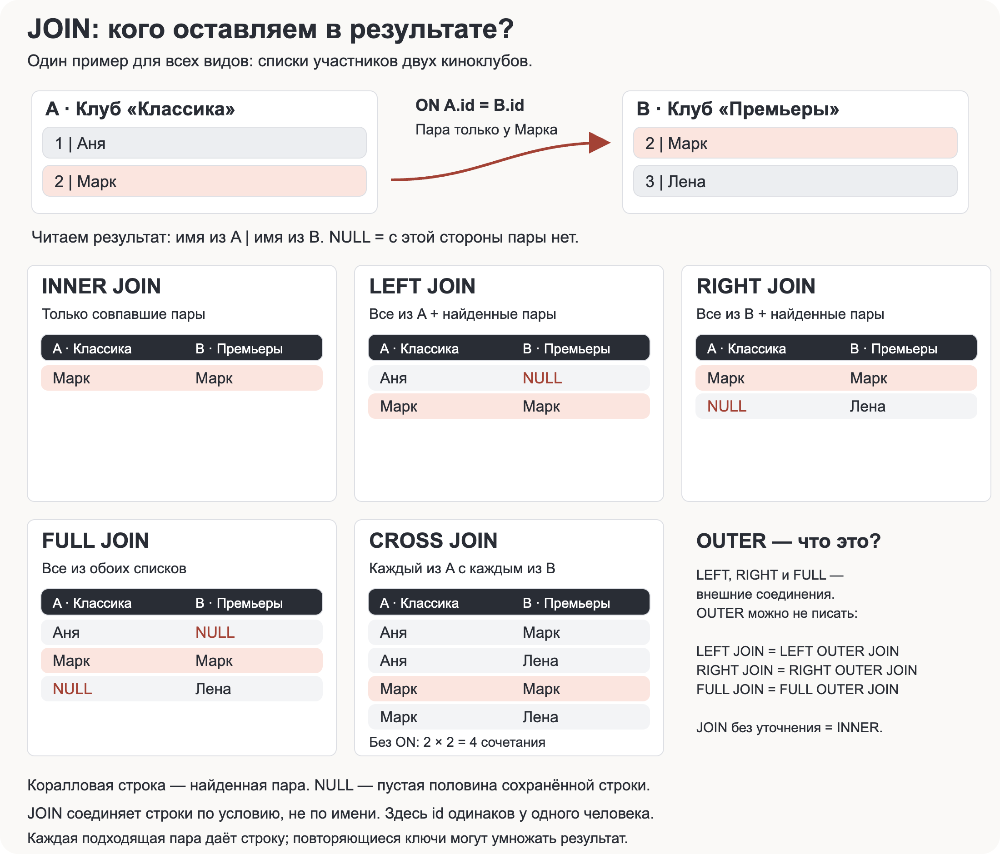
<p style="margin:10px 0 15px;line-height:1.65"><strong>Как собрать JOIN:</strong> определить одну строку результата → найти ключи связи → написать <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON</code> → выбрать столбцы. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON</code> задаёт пары, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code> фильтрует соединённые строки. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">JOIN</code> без уточнения — это <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">INNER JOIN</code>.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Все основные JOIN на одном наборе</h3>
<p style="margin:10px 0 15px;line-height:1.65">Слева <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">L.id = {1, 2}</code>, справа <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">R.id = {2, 3}</code>. Соединяем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">L.id = R.id</code>. В парах ниже первое число — левый ID, второе — правый.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Тип</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Что попадёт</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Пары в результате</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">INNER JOIN</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Только совпавшие пары</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 2)</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Пары + все строки слева без пары</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(1, NULL)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 2)</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">RIGHT JOIN</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Пары + все строки справа без пары</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 2)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(NULL, 3)</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">FULL JOIN</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Пары + строки без пары с обеих сторон</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(1, NULL)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 2)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(NULL, 3)</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">CROSS JOIN</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Каждая левая строка с каждой правой</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(1, 2)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(1, 3)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 2)</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">(2, 3)</code></td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Это состав строк, <strong>не обещанный порядок вывода</strong>. Для порядка нужен ORDER BY. У INNER/LEFT/RIGHT/FULL задаём условие ON; у CROSS JOIN его нет. Слово OUTER в LEFT/RIGHT/FULL OUTER JOIN можно опустить.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Как выбрать:</strong> нужны только совпадения → INNER; важны все карточки каталога → каталог слева и LEFT; нужны несовпадения с обеих сторон → FULL; все комбинации вариантов → CROSS. RIGHT можно переписать как LEFT с переставленными источниками.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Чем задавать связь</h3>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Запись</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Что означает</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON v.title_id = t.title_id</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Явное условие; имена столбцов могут различаться</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">USING (title_id)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Равенство одноимённых столбцов; при SELECT * ключ выводится один раз</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NATURAL JOIN</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">USING по всем совпадающим именам; новая одноимённая колонка может неожиданно изменить связь</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Здесь используем <strong>ON</strong>. Он допускает несколько условий и сравнения, кроме равенства. FK помогает понять связь, но JOIN технически не требует объявленного внешнего ключа.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Self join</strong> — та же таблица в двух ролях: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">users AS a JOIN users AS b ON a.city = b.city AND a.user_id &lt; b.user_id</code> найдёт пары разных пользователей из одного города без зеркальных повторов. Псевдонимы различают роли.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Сколько строк получится?</strong> Если одному значению ключа соответствуют 2 строки слева и 3 справа, получится 6 пар. Если условие забыто или неверно, отчёт разрастается. JOIN добавляет связанные столбцы; <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">UNION ALL</code> решает другую задачу — складывает строки совместимых результатов друг под другом.</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Чьё имя стоит за ID</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> покажите просмотры пользователя № 3 вместе с его именем.</p>
<p style="margin:10px 0 15px;line-height:1.65">Основная строка — просмотр. По user_id находим пользователя и добавляем имя. WHERE оставляет только ID 3. Имя может повторяться: у пользователя несколько разных запусков. Это соединение двух таблиц; в задаче добавится третья.</p>
</div>

In [ ]:
%%sql
SELECT v.view_id, u.name, v.watched_minutes
-- v и u — короткие имена источников; точка указывает столбец.
FROM views AS v
-- Соединяем просмотр с пользователем по ID.
INNER JOIN users AS u ON u.user_id = v.user_id
-- Оставляем просмотры пользователя 3.
WHERE v.user_id = 3
-- Сортируем события по ID.
ORDER BY v.view_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что заметить:</strong> «Саша» повторяется рядом с разными view_id — это разные просмотры одного пользователя. DISTINCT скрыл бы часть информации, если убрать ID. Дальше добавим к просмотрам названия произведений.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 3. Восстановить вечер москвичей</h3>
<p style="margin:10px 0 15px;line-height:1.65">Составьте журнал <strong>положительных просмотров пользователей из Москвы за 5–11 октября</strong>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Выведите <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">view_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, имя как <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_name</code>, название как <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">started_at</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">watched_minutes</code>. Нужны три таблицы: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">views</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">users</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">titles</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Сортировка: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">started_at</code> по возрастанию, затем <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">view_id</code>. Повторные запуски сохраняйте: одна строка результата — один запуск.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Выберите одну строку и прочитайте её как событие: кто, что, когда и сколько минут смотрел. Именно такие события лежат в основе агрегированного отчёта.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">Основная таблица — views. Присоедините users по user_id и titles по title_id. Город находится в users.</p></details>
</div>

In [ ]:
%%sql
-- Задача 3. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep4"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 04 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">Те, кого никто не включил</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:57.14%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> В отчёте только по просмотрам не видно произведений, которые никто не запускал. Найдём такие карточки за выбранную неделю, чтобы редакция могла обратить на них внимание.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NULL</code>, условия в <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ON</code> и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code>.</strong></p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code> сначала находит все подходящие пары. Если пары нет, сохраняет левую строку, заполняя правые столбцы NULL.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Левая таблица</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Правая таблица</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">INNER JOIN</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">LEFT JOIN</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Аня</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Два просмотра</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Две строки</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Две строки</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Марк</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет просмотров</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет строки</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одна строка, поля просмотра — NULL</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>NULL — отсутствие значения, не 0 и не пустая строка.</strong> Проверки: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">IS NULL</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">IS NOT NULL</code>; не <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">= NULL</code>. Обычное сравнение с NULL даёт «неизвестно», а <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code> оставляет только истину.</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">ON: какие правые строки подходят в пару?
    ↓
LEFT JOIN: если пары нет — сохранить левую строку с NULL справа
    ↓
WHERE: какие строки результата оставить?
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Условие по правой таблице в <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code>, например <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">v.watched_minutes &gt; 0</code>, отсеет строки с NULL. Если нужно сохранить всех слева, ограничьте подходящие правые строки <strong>в ON</strong>.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">NULL и отсутствие пары</h3>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Проверка</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Результат</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NULL = 0</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NULL = NULL</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NULL &gt; 5</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Неизвестно, а не истина</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NULL IS NULL</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Истина</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COALESCE(NULL, 0)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">0</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">NULL может означать неизвестное значение в исходных данных <strong>или</strong> отсутствие правой строки после внешнего JOIN. Чтобы найти именно отсутствие строки, проверяем правый первичный ключ: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">v.view_id IS NULL</code>. Проверка nullable-поля, например комментария, не различила бы «строки нет» и «строка есть, но комментарий не заполнен».</p>
<p style="margin:10px 0 15px;line-height:1.65">Для INNER JOIN перенос простого фильтра между ON и WHERE обычно сохраняет результат. Для LEFT/RIGHT/FULL это не общее правило: сначала определяется наличие пары, потом WHERE может удалить сохранённую строку.</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Долгие просмотры без потери пользователей</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> у кого были запуски продолжительностью не менее 150 минут? Покажем все восемь пользователей, даже если такого запуска нет.</p>
<p style="margin:10px 0 15px;line-height:1.65">Ограничение минут стоит в ON: оно определяет подходящую пару. Поэтому человек без длинного просмотра остаётся, а view_id у него будет NULL. Здесь берём всю историю, без недельного фильтра.</p>
</div>

In [ ]:
%%sql
SELECT u.user_id, u.name, v.view_id
FROM users AS u
-- Сохраняем всех пользователей, даже без подходящих просмотров.
LEFT JOIN views AS v
-- Пара подходит, если совпал ID и просмотр длился ≥ 150 минут.
  ON v.user_id = u.user_id AND v.watched_minutes >= 150
-- Сначала пользователь, затем его просмотр.
ORDER BY u.user_id, v.view_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что видно:</strong> длинные просмотры есть у Ани, Марка и Лены; остальные пользователи сохранены с NULL. Если перенести условие минут в WHERE, эти остальные исчезнут. В задаче воспользуемся отсутствием пары, чтобы найти забытые фильмы.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 4. Забытые карточки недели</h3>
<p style="margin:10px 0 15px;line-height:1.65">Найдите произведения, у которых <strong>не было ни одного запуска за 5–11 октября</strong>. Здесь любой запуск считается, <strong>включая нулевые минуты</strong>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Выведите <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">kind</code>; сортируйте по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>. Произведения со старыми просмотрами, но без запусков на выбранной неделе, тоже должны попасть. Используйте <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Выберите одну карточку для дополнительной проверки редакцией. Отсутствие запусков видно из данных; причину предстоит выяснить отдельно.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">Слева titles. В ON — связь по title_id и границы недели. После соединения оставьте строки, где v.view_id IS NULL.</p></details>
</div>

In [ ]:
%%sql
-- Задача 4. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep5"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 05 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">Полный отчёт, включая нули</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:71.43%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> Соберём основной отчёт для редакции: одна строка на каждое произведение, запуски, разные зрители и минуты за неделю. Он позволит сравнить популярность и увидеть нули.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: JOIN + агрегация.</strong> Сначала соединяем строки, затем группируем.</p>
<p style="margin:10px 0 15px;line-height:1.65">После <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code> у произведения без просмотров есть одна сохранённая строка:</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">title_id</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">view_id</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">watched_minutes</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">120</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">NULL</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">NULL</td>
</tr>
</tbody>
</table></div>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Выражение</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Результат</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Почему</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(*)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">1</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Сохранённая строка существует</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(v.view_id)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">0</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Непустых ID просмотров нет</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SUM(v.watched_minutes)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">NULL</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Нет непустых чисел</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COALESCE(SUM(v.watched_minutes), 0)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">0</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">COALESCE берёт первое не-NULL значение</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Группируем по ID и названию: ID различает произведения, название делает отчёт понятным. Не соединяйте одновременно две связи «один ко многим» без подготовки: 3 просмотра × 2 оценки дадут 6 строк и завышенные суммы. Независимые показатели сначала агрегируют отдельно.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Как не получить завышенные суммы</h3>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">Один фильм → 3 просмотра
          → 2 оценки
JOIN обеих подробных таблиц → 3 × 2 = 6 строк
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Каждый просмотр повторится дважды, каждая оценка — трижды. Для отчёта по фильму сначала получите <strong>одну строку на фильм</strong> отдельно из просмотров и отдельно из оценок, затем соедините итоги. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(DISTINCT view_id)</code> иногда чинит конкретный счётчик, но не исправляет автоматически SUM и AVG.</p>
<p style="margin:10px 0 15px;line-height:1.65">Ставьте COALESCE осмысленно: отсутствие просмотров можно представить нулём запусков. Отсутствие оценок не обязательно означает «средняя оценка 0» — это может быть «ещё не оценено».</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Итоги по каждому зрителю</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> сколько запусков и минут у каждого пользователя за всю историю, включая тех, кто ничего не запускал?</p>
<p style="margin:10px 0 15px;line-height:1.65">LEFT JOIN сохраняет пользователей. GROUP BY собирает строки по ID и имени. COUNT(v.view_id) считает реальные запуски; COALESCE превращает отсутствие суммы в ноль. В этом примере считаем и запуски с нулевыми минутами.</p>
</div>

In [ ]:
%%sql
SELECT u.user_id, u.name,
-- Считаем реальные ID просмотров; NULL не учитывается.
       COUNT(v.view_id) AS starts_count,
-- Сумма минут; при отсутствии значений заменяем NULL на 0.
       COALESCE(SUM(v.watched_minutes), 0) AS total_minutes
FROM users AS u
-- Сохраняем и пользователей без просмотров.
LEFT JOIN views AS v ON v.user_id = u.user_id
-- Сворачиваем строки в один итог на человека.
GROUP BY u.user_id, u.name
ORDER BY u.user_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что видно:</strong> у Иры ноль запусков и минут; два пользователя Саша остаются отдельными строками благодаря разным ID. COUNT(*) дал бы Ире ложную единицу. Теперь составим такой же полный отчёт по произведениям.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 5. Народная любовь или один преданный фанат?</h3>
<p style="margin:10px 0 15px;line-height:1.65">Для <strong>всех 16 произведений</strong> составьте отчёт за 5–11 октября. Считайте только запуски с положительным временем.</p>
<p style="margin:10px 0 15px;line-height:1.65">Столбцы: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">starts_count</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">viewers_count</code> (разные зрители), <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">total_minutes</code>. Если подходящих просмотров нет, все три показателя должны быть <strong>0</strong>.</p>
<p style="margin:10px 0 15px;line-height:1.65">Сортируйте по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">starts_count DESC</code>, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">viewers_count DESC</code>, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Сравните два произведения по запускам и разным зрителям. Кого предложите в подборку «Популярно у зрителей» и на какой показатель опираетесь?</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">Фильтры периода и минут — в ON. COUNT(v.view_id), COUNT(DISTINCT v.user_id), COALESCE(SUM(...), 0). Не COUNT(*).</p></details>
</div>

In [ ]:
%%sql
-- Задача 5. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep6"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 06 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">CTE и подзапрос</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:85.71%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> После просмотров перейдём к оценкам. Найдём пользователей, чьё личное среднее выше общего: это поможет редакции учитывать привычки авторов отзывов.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: CTE + скалярный подзапрос.</strong> Когда запрос содержит несколько шагов, каждому удобно дать имя; когда нужен вычисленный порог, его может вернуть другой SELECT.</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-text" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">WITH user_stats AS (SELECT ...)
         ↓ временное имя результата внутри одного SQL-запроса
SELECT ... FROM user_stats WHERE ...;
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">CTE — не новая постоянная таблица и не отдельная команда. Закрыли скобку — продолжаем основной SELECT; точка с запятой только в конце всего запроса. Имя CTE доступно основному запросу и последующим CTE в том же WITH.</p>
<p style="margin:10px 0 15px;line-height:1.65">Псевдонимы столбцов, заданные внутри CTE, снаружи становятся обычными входными столбцами: поэтому внешний WHERE уже может использовать starts_count. Слово AS в WITH name AS (...) обязательно. Несколько CTE перечисляют через запятую. CTE помогает читать запрос, но сам по себе не гарантирует ускорения или материализации.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Что такое подзапрос</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Подзапрос — SELECT внутри другого SQL-запроса.</strong> Его результат используется внешним запросом как число, набор значений или таблица. В нашей задаче нужен один числовой порог.</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-sql" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">WHERE score &gt; (SELECT AVG(score) FROM ratings)
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Читаем: «оставить оценку выше среднего по всем оценкам». Внутренний SELECT возвращает одно число; внешний сравнивает с ним строки. Это <strong>скалярный подзапрос</strong>: один столбец, не больше одной строки. Больше одной строки — ошибка; ноль строк — NULL. AVG без GROUP BY всегда даёт одну строку; если исходных оценок нет, в ней NULL.</p>
<p style="margin:10px 0 15px;line-height:1.65">В задаче CTE отвечает за <strong>среднее каждого пользователя</strong>, подзапрос — за <strong>общее среднее по всем отдельным оценкам</strong>. Эти наборы нельзя путать: среднее средних пользователей даёт им одинаковый вес, а среднее всех оценок — нет.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">CTE и подзапрос — как связаны</h3>
<p style="margin:10px 0 15px;line-height:1.65">CTE даёт имя результату SELECT, чтобы использовать его дальше как источник. Вложенный SELECT в FROM делает похожую работу, но располагается прямо внутри основного запроса. <strong>В обоих случаях выходной псевдоним внутреннего SELECT становится входным столбцом внешнего.</strong></p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-sql" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">WITH a AS (SELECT ...),
     b AS (SELECT ... FROM a)
SELECT ... FROM b;
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">Это схема нескольких шагов, не готовый запрос. CTE существует только в пределах этой команды. Для наших задач не нужны RECURSIVE, MATERIALIZED и создание таблиц.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Справка после занятия: где бывает подзапрос</h3>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Форма</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Как понимать</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">score &gt; (SELECT AVG(score) FROM ratings)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одно вычисленное значение для сравнения</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">title_id IN (SELECT title_id FROM ratings)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Принадлежит ли ID набору из одного столбца?</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">EXISTS (SELECT 1 FROM views v WHERE v.title_id = t.title_id)</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Есть ли хотя бы одна подходящая строка?</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">FROM (SELECT ...) AS q</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Результат внутреннего запроса становится таблицей-источником</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Подзапрос, который обращается к строке внешнего запроса (как <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">t.title_id</code> в EXISTS), называется <strong>коррелированным</strong>. Мысленно проверяем его для каждой внешней строки; СУБД может оптимизировать выполнение.</p>
<p style="margin:10px 0 15px;line-height:1.65"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NOT EXISTS</code> удобно ищет отсутствие связанных строк. С <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">NOT IN</code> осторожнее: NULL в наборе может сделать проверку неизвестной и убрать ожидаемые строки.</p>
<p style="margin:10px 0 15px;line-height:1.65">Если нужен псевдоним результата в WHERE, вынесите вычисление внутрь: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT q.hours FROM (SELECT duration_minutes / 60.0 AS hours FROM titles) AS q WHERE q.hours &gt; 2</code>. Для внешнего запроса hours — уже входной столбец.</p>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Постоянные зрители в два шага</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> у каких пользователей не меньше пяти запусков за всю историю?</p>
<p style="margin:10px 0 15px;line-height:1.65">В CTE user_stats считаем число запусков на пользователя. Основной SELECT обращается к этому результату и фильтрует starts_count в WHERE. В отличие от соседних выражений одного SELECT, здесь starts_count — уже готовый входной столбец.</p>
</div>

In [ ]:
%%sql
-- CTE: называем промежуточный результат user_stats; AS обязательно.
WITH user_stats AS (
-- Внутри считаем число запусков каждого пользователя.
    SELECT user_id, COUNT(*) AS starts_count
    FROM views
    GROUP BY user_id
)
-- Снаружи читаем готовые столбцы CTE.
SELECT user_id, starts_count
FROM user_stats
-- starts_count уже входной столбец: его можно использовать в WHERE.
WHERE starts_count >= 5
-- Сначала больше запусков, затем меньше ID.
ORDER BY starts_count DESC, user_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что заметить:</strong> user_stats не появляется в базе как постоянная таблица. Весь текст от WITH до финального SELECT — один запрос. Сначала сформировали starts_count, затем использовали его в WHERE. В задаче CTE посчитает личные средние, а вложенный SELECT вычислит общий порог по всем оценкам.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 6. Клуб щедрых кинокритиков</h3>
<p style="margin:10px 0 15px;line-height:1.65">Сделайте отчёт в два шага через <strong>CTE <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_scores</code></strong>.</p>
<ol>
<li style="margin:6px 0;padding-left:3px">Внутри CTE по таблице <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ratings</code> получите одну строку на <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ratings_count</code> — количество оценок и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">avg_score</code> — среднюю оценку.</li>
<li style="margin:6px 0;padding-left:3px">Во внешнем запросе добавьте имя из <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">users</code> и оставьте пользователей с <strong>не менее чем двумя оценками</strong>, чья средняя оценка <strong>строго выше среднего по всем 18 отдельным оценкам сервиса</strong>. Общий порог вычислите <strong>скалярным подзапросом по ratings</strong>. Условия на оба показателя напишите во внешнем WHERE.</li>
</ol>
<p style="margin:10px 0 15px;line-height:1.65">Выведите <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_name</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ratings_count</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">avg_score</code> (округлить до двух знаков только при выводе). Сортируйте по неокруглённому среднему по убыванию, затем по количеству оценок по убыванию, затем по ID. Период просмотров здесь не применяется.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Выберите одного пользователя и объясните, почему он попал в список. Сравнение с общим средним описывает его оценки в этом наборе данных.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">CTE: user_id, COUNT(*) AS ratings_count, AVG(score) AS avg_score с GROUP BY user_id. Снаружи присоедините users. Условие среднего: s.avg_score &gt; (SELECT AVG(score) FROM ratings). Не AVG(avg_score) по CTE: это другой показатель.</p></details>
</div>

In [ ]:
%%sql
-- Задача 6. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-episode" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><p style="margin:10px 0 15px;line-height:1.65"><a id="ep7"></a></p>
<div style="background:#292D35;border-radius:15px;padding:25px 28px;margin:5px 0 25px;color:white"><div style="font:600 11px system-ui;letter-spacing:2.5px;color:#F08272;margin-bottom:13px">ЭПИЗОД 07 / 07</div><h2 style="font:700 30px/1.2 system-ui;color:#ffffff;letter-spacing:-0.6px;margin:0 0 18px">У каждого своя шкала</h2><div style="height:3px;background:#565C68;border-radius:3px"><div style="height:3px;width:100.00%;background:#F08272;border-radius:3px"></div></div></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Зачем этот шаг:</strong> Теперь посмотрим на каждую оценку рядом с личным средним её автора. Так редакция увидит, что понравилось человеку сильнее или слабее его обычного уровня.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Тема: оконные функции, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">OVER (PARTITION BY ...)</code>.</strong></p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Исходные оценки</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">GROUP BY user_id</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">AVG(score) OVER (PARTITION BY user_id)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Аня: 9, 10, 8, 7</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одна строка: Аня, 8.5</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Четыре строки: рядом с каждой оценкой 8.5</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>GROUP BY сворачивает строки. Окно добавляет расчёт, сохраняя строки.</strong> <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">PARTITION BY user_id</code> означает «посчитать отдельно для каждого пользователя». <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">OVER ()</code> — по всем строкам, оставшимся после фильтрации и группировки.</p>
<pre style="background:#292D35;color:#FAF9F7;padding:19px 22px;border-radius:12px;overflow:auto;font-size:14px;line-height:1.7;margin:18px 0;border-left:4px solid #F08272;white-space:pre"><code class="language-sql" style="font-family:ui-monospace,Menlo,Consolas,monospace;color:#FAF9F7 !important;background:transparent !important;padding:0">AVG(score) OVER (PARTITION BY user_id)
│               └── по чьим строкам считать
└── что посчитать
</code></pre>
<p style="margin:10px 0 15px;line-height:1.65">В этом блоке не добавляем <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code> внутрь OVER: оно может изменить рамку расчёта. Внешний <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY</code> только сортирует готовый результат. Окна недоступны в WHERE и HAVING этого же уровня; для фильтрации результата окна нужен внешний запрос.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Группа, окно, сортировка — три разных действия</h3>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Приём</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Сколько строк остаётся</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Для чего</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY user_id</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Одна на пользователя</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Итоговый отчёт</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AVG(score) OVER (PARTITION BY user_id)</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Каждая оценка</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Личный средний рядом с оценкой</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AVG(score) OVER ()</code></td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Каждая оценка</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Общее среднее рядом с оценкой</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Внешний <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ORDER BY user_id</code></td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Число строк не меняется</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Порядок показа</td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65">Окно видит строки <strong>после WHERE</strong>. Если сначала убрать оценки ниже 8, среднее окна будет считаться только по оставшимся оценкам. Если нужно сначала вычислить среднее по всем, а потом отфильтровать строки, окно ставим во внутренний запрос, фильтр — во внешний.</p>
<p style="margin:10px 0 15px;line-height:1.65">В SELECT разрешено несколько окон. Их выражения можно повторять, но использовать только что заданный псевдоним в соседнем выражении нельзя. <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">PARTITION BY</code> не сортирует строки и не объединяет их в одну.</p>
<details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Что изучать дальше</summary><p style="margin:10px 0 15px;line-height:1.65">ROW_NUMBER нумерует строки в заданном порядке; RANK оставляет пропуски после равных мест, DENSE_RANK — нет. ORDER BY внутри OVER и рамки ROWS/RANGE позволяют накопительные итоги. Для текущей задачи достаточно агрегата с PARTITION BY без внутреннего ORDER BY.</p></details>
</div>

<div class="streaming-example" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#F3F4F6;padding:22px 26px;border-radius:14px;border:1px solid #5B606B;border-left:4px solid #5B606B;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#5B606B;margin-bottom:12px">СМОТРИМ ВМЕСТЕ · ГОТОВЫЙ ПРИМЕР</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Разобранный пример · Личный итог рядом с каждым запуском</h3>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Вопрос:</strong> покажите все запуски пользователей 3 и 5, добавив к каждому их суммарные минуты.</p>
<p style="margin:10px 0 15px;line-height:1.65">WHERE оставляет этих двух пользователей. PARTITION BY user_id считает сумму отдельно для каждого из них. Окно не сворачивает запуски: SUM появится рядом с каждой исходной строкой.</p>
</div>

In [ ]:
%%sql
SELECT view_id, user_id, watched_minutes,
-- Сумма по пользователю рядом с каждым просмотром; строки сохраняются.
       SUM(watched_minutes) OVER (PARTITION BY user_id) AS user_total_minutes
FROM views
-- Фильтр применяется до окна: оставляем пользователей 3 и 5.
WHERE user_id IN (3, 5)
-- Сортируем вывод; это не ORDER BY внутри окна.
ORDER BY user_id, view_id;

<div class="streaming-observation" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FAF9F7;padding:22px 26px;border-radius:14px;border:1px solid #6C625C;border-left:4px solid #6C625C;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#6C625C;margin-bottom:12px">ЧИТАЕМ РЕЗУЛЬТАТ</div><p style="margin:10px 0 15px;line-height:1.65"><strong>Что заметить:</strong> user_total_minutes повторяется внутри одного пользователя, но view_id остаются отдельными. WHERE здесь исключил других пользователей целиком, поэтому личные суммы 3 и 5 не изменились. В задаче используем окно для среднего и отклонения оценки.</p>
</div>

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px"><div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ВАША ОЧЕРЕДЬ · ОДНО ЗАДАНИЕ НА ДВОИХ</div><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Задача 7. Личная шкала кинокритика</h3>
<p style="margin:10px 0 15px;line-height:1.65">Сохраните <strong>все 18 отдельных оценок</strong>. Для каждой выведите <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">rating_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">score</code>, <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_avg</code> — среднюю оценку этого пользователя, и <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">delta</code> — оценка минус его среднее.</p>
<p style="margin:10px 0 15px;line-height:1.65">Оба вычисления округлите до двух знаков. Для <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">delta</code> сначала вычитайте <strong>неокруглённое</strong> среднее, затем округляйте разность. Сортируйте по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">user_id</code>, затем по <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">rating_id</code>. Используйте только <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ratings</code>; JOIN здесь не нужен.</p>
<p style="margin:10px 0 15px;line-height:1.65">Подсказка по синтаксису округления: <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">ROUND(выражение, 2)</code>.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>После запроса — к общему решению:</strong> Найдите положительное и отрицательное delta. Объясните, какая оценка выше обычной для её автора, а какая ниже.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Оба студента решают это же задание:</strong> один пишет запрос на доске, второй — в ячейке ниже. Запускаем после двух первых попыток.</p>
</div>

<div class="streaming-hint" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Подсказка, если застряли</summary><p style="margin:10px 0 15px;line-height:1.65">AVG(score) OVER (PARTITION BY user_id). Псевдоним user_avg не доступен соседнему выражению SELECT: повторите окно в delta.</p></details>
</div>

In [ ]:
%%sql
-- Задача 7. Напишите запрос ниже.
-- Комментарии можно оставить.

<div class="streaming-task" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#FFF5F2;padding:22px 26px;border-radius:14px;border:1px solid #A34235;border-left:4px solid #A34235;margin:5px 0 12px">
<a id="editor-brief"></a>
<div style="font:700 11px system-ui;letter-spacing:1.7px;color:#A34235;margin-bottom:12px">ФИНАЛ · РЕШЕНИЕ ДЛЯ РЕДАКЦИИ</div>
<h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">Что предложим зрителям — и почему?</h2>
<p style="margin:10px 0 15px;line-height:1.65">Вернитесь к главному вопросу занятия. Используйте результаты своих запросов и заполните записку ниже: <strong>по 1–2 предложения на каждый пункт</strong>. Формула вывода: <strong>предложение → конкретные числа → объяснение</strong>.</p>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead><tr><th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Часть записки</th><th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">На что опереться</th></tr></thead>
<tbody>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><strong>1. Короткий вечер.</strong> Предложите один фильм для подборки «Успеть до полуночи».</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Задача 1: название, длительность, рейтинг каталога и оставшиеся минуты.</td></tr>
<tr><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><strong>2. Популярно у зрителей.</strong> Сравните два произведения и выберите одно по охвату аудитории.</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Задачи 2 и 5: число запусков и разных зрителей за 5–11 октября. Журнал из задачи 3 помогает проверить отдельные события московских пользователей.</td></tr>
<tr><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><strong>3. Без внимания.</strong> Выберите произведение без запусков, которое редакции стоит дополнительно изучить.</td><td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Задача 4: отсутствие любых запусков за неделю. Сформулируйте вопрос о возможной причине; сами данные её не объясняют.</td></tr>
<tr><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top"><strong>4. Оценки в контексте.</strong> Покажите, зачем учитывать личную шкалу автора.</td><td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top">Задача 6: один пользователь с высоким средним. Задача 7: пример положительного и отрицательного delta с указанием rating_id и user_id.</td></tr>
</tbody></table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Проверьте себя:</strong> у каждого вывода есть источник и конкретные значения; запуски и разные зрители различаются; период указан там, где он применяется. Для оценок используется весь учебный набор. Выбор редакции может различаться — важно обосновать его данными.</p>
</div>


<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Наша записка редакции</h3>
<p style="margin:10px 0 15px;line-height:1.65">Дважды щёлкните по этой Markdown-ячейке, замените пропуски своими выводами и нажмите <strong>Shift + Enter</strong>.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>1. Короткий вечер.</strong> Предлагаем фильм ___: длительность ___ минут, рейтинг каталога ___, после него останется ___ минут. Поэтому ___.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>2. Популярно у зрителей.</strong> У ___ — ___ запусков и ___ разных зрителей; у ___ — ___ и ___. Для главной выбираем ___, потому что ___.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>3. Без внимания.</strong> У ___ не было запусков за 5–11 октября. Редакции стоит проверить ___.</p>
<p style="margin:10px 0 15px;line-height:1.65"><strong>4. Оценки в контексте.</strong> Пользователь ___ попал в список щедрых критиков, потому что ___. У оценки rating_id ___ / user_id ___ отклонение ___, а у rating_id ___ / user_id ___ — ___. Это означает ___.</p>
</div>


<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><h2 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:27px">Титры. Одна страница перед следующим запросом</h2>
<div style="overflow-x:auto;width:100%"><table style="width:100%;border-collapse:separate;border-spacing:0;border:1px solid #DDDFE4;border-radius:12px;overflow:hidden;font-size:15px;line-height:1.55;margin:18px 0 22px">
<thead>
<tr>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Нужно…</th>
<th style="background:#292D35;color:white;text-align:left;padding:12px 15px;font-weight:600;border:0">Инструмент</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Выбрать столбцы / строки</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">SELECT</code> / <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Понятно назвать результат</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">AS</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Получить один итог на группу</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">GROUP BY</code> + агрегаты</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Отобрать группы</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">HAVING</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Найти пары в таблицах</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">INNER JOIN ... ON</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Сохранить строки без пары</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN ... ON</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Найти отсутствие пары</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">LEFT JOIN</code> + <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WHERE right_id IS NULL</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Посчитать реальные правые строки</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(right_id)</code>, не <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COUNT(*)</code></td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Подставить значение вместо NULL</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">COALESCE(value, 0)</code></td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Вычислить порог из данных</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Подзапрос</td>
</tr>
<tr>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Назвать промежуточный результат запроса</td>
<td style="background:#ffffff;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;"><code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">WITH name AS (...)</code> — CTE</td>
</tr>
<tr>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;font-weight:500;">Посчитать итог, сохранив строки</td>
<td style="background:#F2F3F5;color:#292D35;padding:12px 15px;border:0;border-bottom:1px solid #E5E6E9;vertical-align:top;">Агрегат + <code style="font-family:ui-monospace,Menlo,Consolas,monospace;font-size:0.91em;color:#333740;background:#ECEEF1;padding:2px 5px;border-radius:4px">OVER (PARTITION BY ...)</code></td>
</tr>
</tbody>
</table></div>
<p style="margin:10px 0 15px;line-height:1.65"><strong>Перед запуском:</strong> что означает одна строка результата? Какие строки обязаны остаться? По каким ID соединяем? Нет ли лишнего размножения строк? Нужны запуски или разные зрители?</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Что теперь умеем</h3>
<p style="margin:10px 0 15px;line-height:1.65">Мы прошли путь от вопроса редакции до проверяемого вывода: отобрали фильмы, посчитали аудиторию, сохранили нули и добавили контекст к оценкам. У каждого предложения в итоговой записке есть опора в результате SQL-запроса. Теперь можно и спать.</p>
<h3 style="color:#292D35;font-family:system-ui,-apple-system,sans-serif;letter-spacing:-0.6px;font-weight:700;line-height:1.25;margin:24px 0 15px;font-size:21px">Источники и технические заметки</h3>
<p style="margin:10px 0 15px;line-height:1.65">Правила SQL сверены с <a href="https://www.postgresql.org/docs/current/sql-select.html" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">PostgreSQL SELECT</a>. Автоматический локальный сервер: <a href="https://pypi.org/project/pgserver/" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">pgserver</a> / <a href="https://pypi.org/project/pgembed/" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">pgembed</a>. Кадры игры и видеофрагмент встроены в файл. Для кнопок требуется запущенное Python-ядро; статический просмотр ipynb не выполняет игру.</p>
<p style="margin:10px 0 15px;line-height:1.65">Справочные разделы PostgreSQL: <a href="https://www.postgresql.org/docs/current/queries-table-expressions.html" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">соединения и группировка</a>, <a href="https://www.postgresql.org/docs/current/functions-aggregate.html" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">агрегаты</a>, <a href="https://www.postgresql.org/docs/current/tutorial-window.html" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">оконные функции</a>.</p>
</div>

<div class="streaming-theory" style="font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,sans-serif;font-size:16px;line-height:1.65;color:#292D35;background:#ffffff;padding:10px 14px;border-radius:14px;margin:5px 0 12px"><details style="background:#F4F4F5;border:1px solid #DEDFE3;border-radius:10px;padding:13px 17px;margin:12px 0;color:#333740"><summary style="font-weight:600;cursor:pointer;color:#4C5059;padding:2px 0">Источники кадров игры</summary><ul><li style="margin:6px 0;padding-left:3px">Начало — <a href="https://shot.cafe/movie/inception-2010" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">страница источника</a></li><li style="margin:6px 0;padding-left:3px">Бойцовский клуб — <a href="https://www.latercera.com/culto/2019/04/08/homoerotismo-fight-club/" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">страница источника</a></li><li style="margin:6px 0;padding-left:3px">Интерстеллар — <a href="https://www.csfd.cz/film/227786-interstellar/galerie/" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">страница источника</a></li><li style="margin:6px 0;padding-left:3px">Друзья — <a href="https://www.thenews.com.pk/latest/1213908-lisa-kudrow-dishes-on-chaos-behind-filming-friends-opening-credits" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">страница источника</a></li><li style="margin:6px 0;padding-left:3px">Шрек — <a href="https://clip.cafe/shrek-2001/such-a-perfect-town/" style="color:#A34235;text-decoration:underline;text-underline-offset:3px">страница источника</a></li></ul></details>
</div>